# 01 - Data acquisition and analysis (Person 1)

Sources: the paper's repository (ratings, line-ups, scores) and the openfootball/england fixture lists (**match dates**).  The paper's files contain no dates and are not in chronological order after 2013/14, so dates are required for leakage-free features.

Rebuild everything with `python -m src.data_preprocessing --fetch --build`.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))   # make `src` importable from notebooks/
import pandas as pd, numpy as np
from IPython.display import Image, display
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
from src.data_preprocessing import read_processed, PROCESSED_DIR, TABLES_DIR

## Data-quality report

In [2]:
print((TABLES_DIR / 'data_quality_report.md').read_text())

# Data-quality report

- **fixtures_total**: 3800
- **fixtures_unmapped_team_names**: 0
- **fixtures_duplicate_pairs**: 0
- **fixtures_missing_values**: 0
- **fixtures_team_twice_same_day**: 0
- **fixtures_teams_not_38_games**: 0
- **fixtures_dates_outside_season_window**: 0
- **paper_rows**: 3791
- **paper_missing_values**: 0
- **paper_duplicate_match_id_rows**: 1
- **paper_distinct_team_names**: 36
- **paper_team_names_not_in_map**: []
- **paper_rows_without_date**: 0
- **paper_duplicate_fixture_rows**: 1
- **score_mismatches_between_sources**: 0
- **score_mismatch_rows**: []
- **duplicate_fixture_paper_rows_dropped**: [434]
- **matches_clean**: 3790
- **fixtures_not_in_paper_dataset**: 10
- **class_counts**: {'H': 1750, 'A': 1100, 'D': 940}
- **class_share**: {'H': 0.4617, 'A': 0.2902, 'D': 0.248}
- **alignment_with_match_vectors**: {'vector_rows': 3791, 'rows_kept_in_matches_clean': 3790, 'kept_rows_with_matching_label': 3790, 'kept_rows_with_label_mismatch': 0, 'rows_removed_as_du

## Clean tables
`fixtures_full` = all 3,800 fixtures (used only for historical form / Elo). `matches_clean` = the 3,790 unique matches in the paper's data (3,791 rows minus one duplicated fixture).

In [3]:
fixtures = read_processed('fixtures_full.csv'); matches = read_processed('matches_clean.csv')
print(fixtures.shape, matches.shape)
matches.head()

(3800, 8) (3790, 13)


,paper_row,match_id,fixture_id,season,date,home_team,away_team,home_team_id,away_team_id,home_goals,away_goals,result,label
0,2,317787,0,0910,2009-08-15,Aston Villa,Wigan,24,194,0,2,A,-1
1,5,317790,1,0910,2009-08-15,Blackburn,Man City,158,167,0,2,A,-1
2,6,317791,2,0910,2009-08-15,Bolton,Sunderland,92,16,0,1,A,-1
3,9,317794,3,0910,2009-08-15,Chelsea,Hull,15,214,2,1,H,1
4,3,317788,4,0910,2009-08-15,Everton,Arsenal,31,13,1,6,A,-1


In [4]:
# the 10 fixtures missing from the paper's data (still used for form / Elo history)
fixtures[~fixtures.fixture_id.isin(matches.fixture_id)][['season','date','home_team','away_team','home_goals','away_goals']]

,season,date,home_team,away_team,home_goals,away_goals
427,1011,2010-09-19,Chelsea,Blackpool,4,0
1067,1112,2012-04-01,Tottenham,Swansea,3,1
2268,1415,2015-05-18,West Brom,Chelsea,3,0
2836,1617,2016-12-26,Swansea,West Ham,1,4
3495,1819,2018-10-06,Tottenham,Cardiff,1,0
3529,1819,2018-11-05,Huddersfield,Fulham,1,0
3560,1819,2018-12-04,Bournemouth,Huddersfield,2,1
3630,1819,2019-01-12,Brighton,Liverpool,0,1
3687,1819,2019-02-24,Arsenal,Southampton,2,0
3737,1819,2019-04-03,Man City,Cardiff,2,0


## Target variable
`H` home goals > away goals, `D` equal, `A` home goals < away goals. Goals are never model inputs.

In [5]:
pd.read_csv(TABLES_DIR / 'dataset_summary.csv', dtype={'season': str})

,season,fixtures_total,matches_in_paper_data,H,D,A,home_win_pct,draw_pct,away_win_pct,avg_goals_per_match
0,0910,380,380,193,96,91,50.8,25.3,23.9,2.77
1,1011,380,379,178,111,90,47.0,29.3,23.7,2.79
2,1112,380,379,170,93,116,44.9,24.5,30.6,2.80
3,1213,380,380,166,108,106,43.7,28.4,27.9,2.80
4,1314,380,380,179,78,123,47.1,20.5,32.4,2.77
5,1415,380,379,171,93,115,45.1,24.5,30.3,2.56
6,1516,380,380,157,107,116,41.3,28.2,30.5,2.70
7,1617,380,379,187,84,108,49.3,22.2,28.5,2.79
8,1718,380,380,173,99,108,45.5,26.1,28.4,2.68
9,1819,380,374,176,71,127,47.1,19.0,34.0,2.84


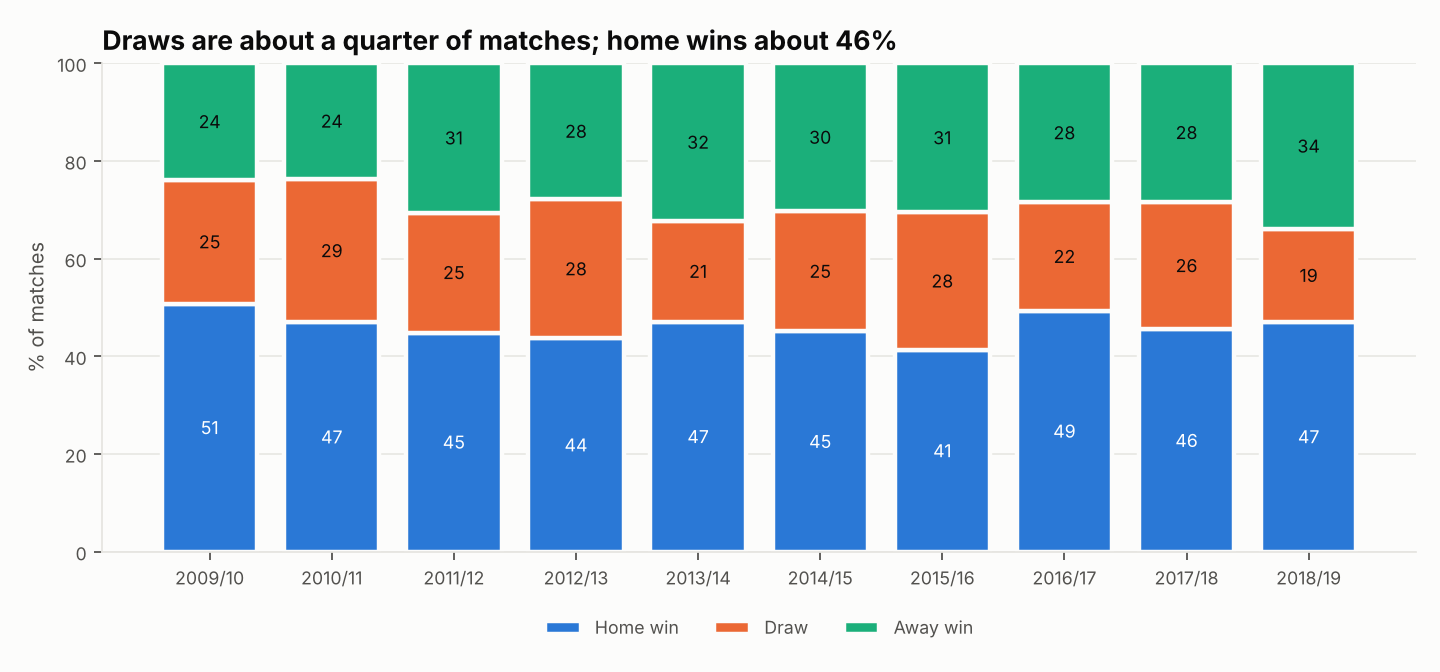

In [6]:
display(Image(str(pathlib.Path.cwd().parent / 'results/figures/01_outcome_share_by_season.png')))